#PROGRAM 2

Using Python, perform exploratory analysis of a multivariate dataset by creating bar, stacked bar, line, scatter, bubble, histogram, box plot, heatmap, radar, pie, tree map, and word cloud visualizations. Examine the visualizations to identify distributions, outliers, trends, correlations, and patterns. Interpret the results to identify important insights from the dataset.

## Working with day.csv

In [2]:
pip install squarify

Day dataset (Bike Sharing) loaded successfully!
Shape: (731, 16)
Columns: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
Shape after removing duplicates: (731, 16)
Missing values:
 0


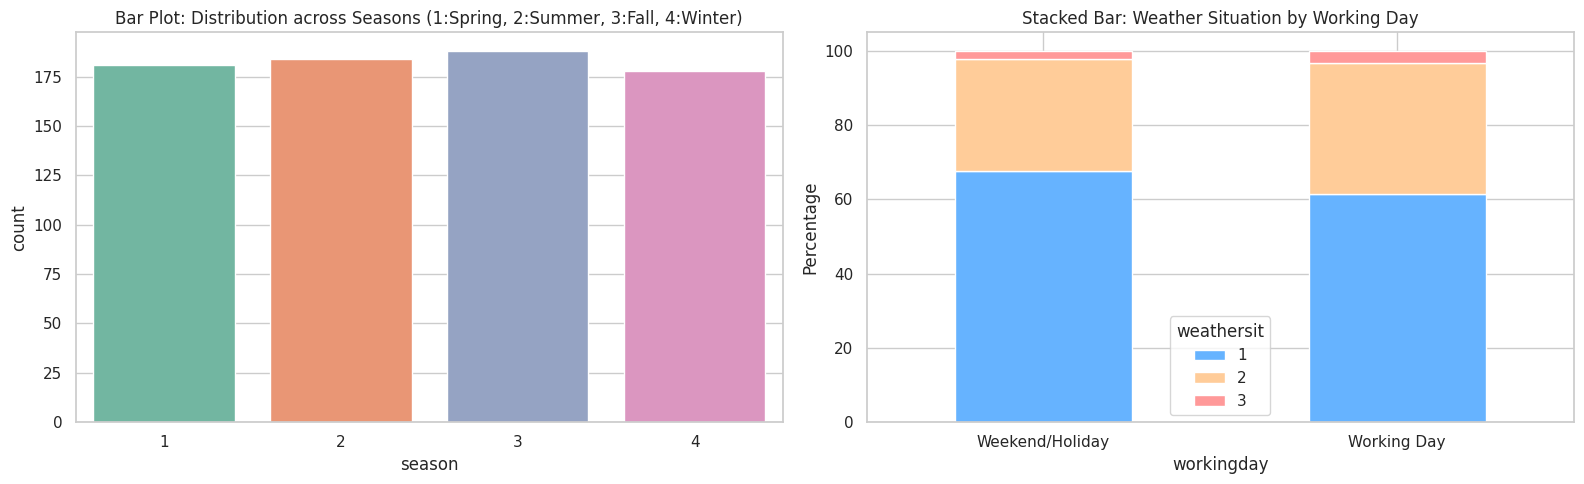

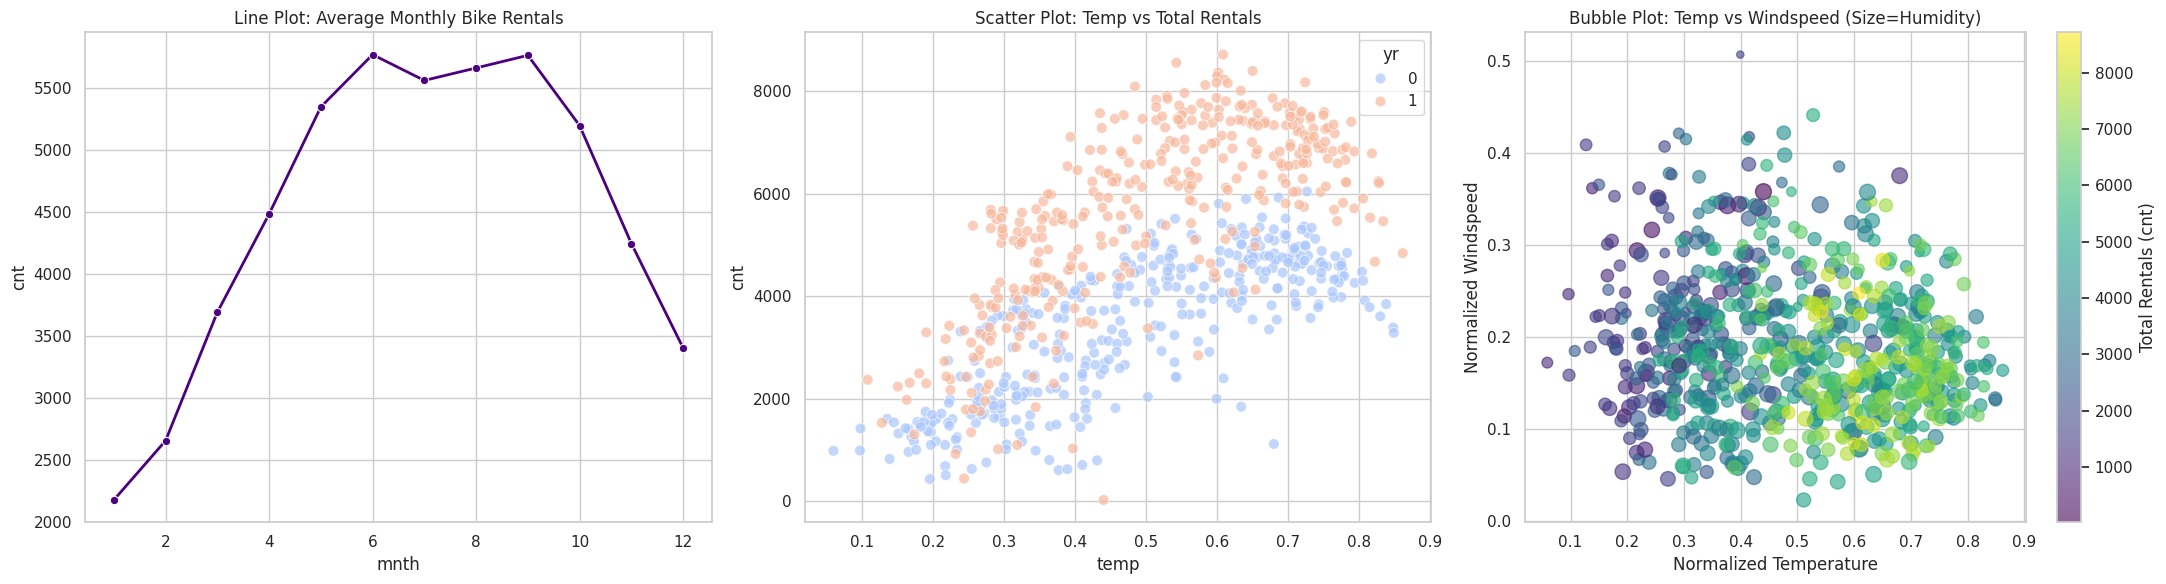

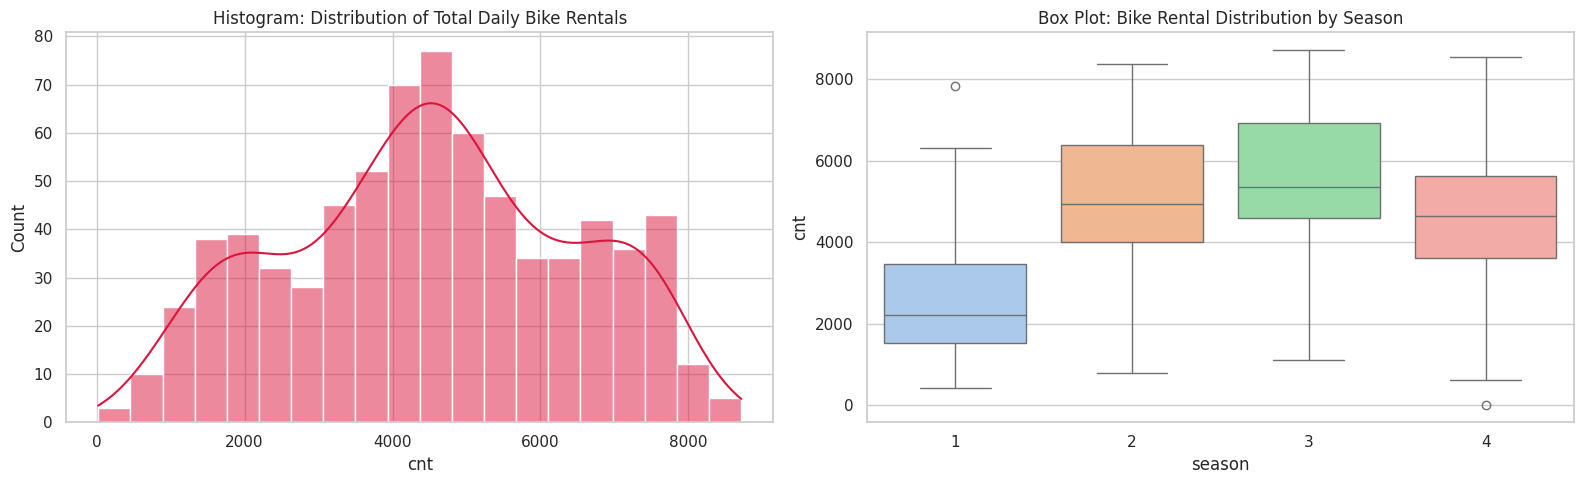

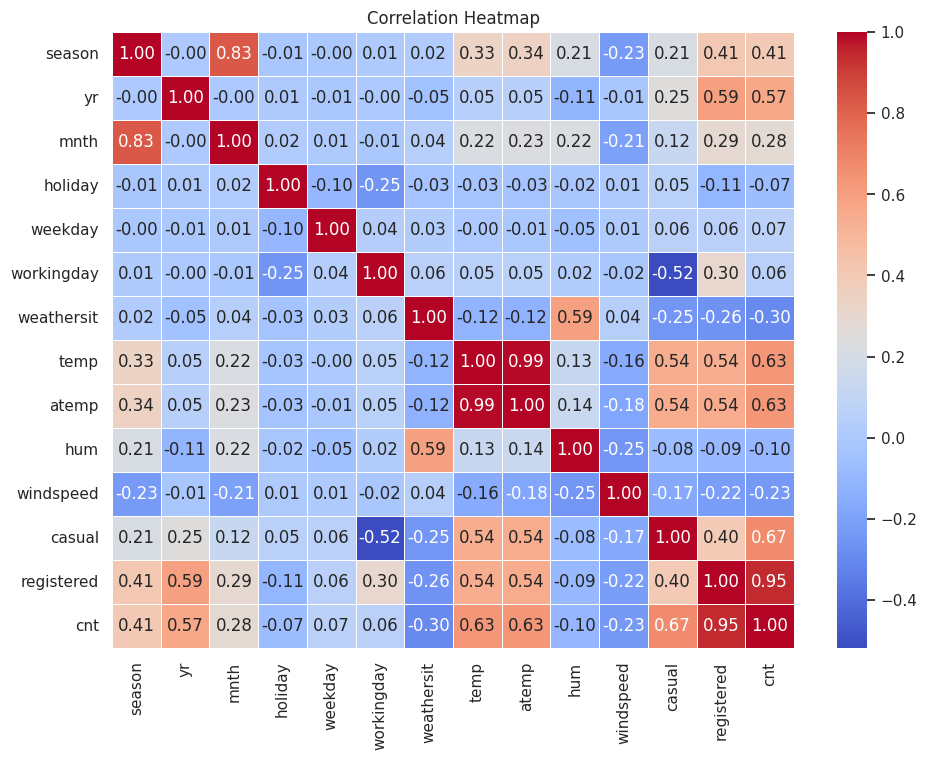

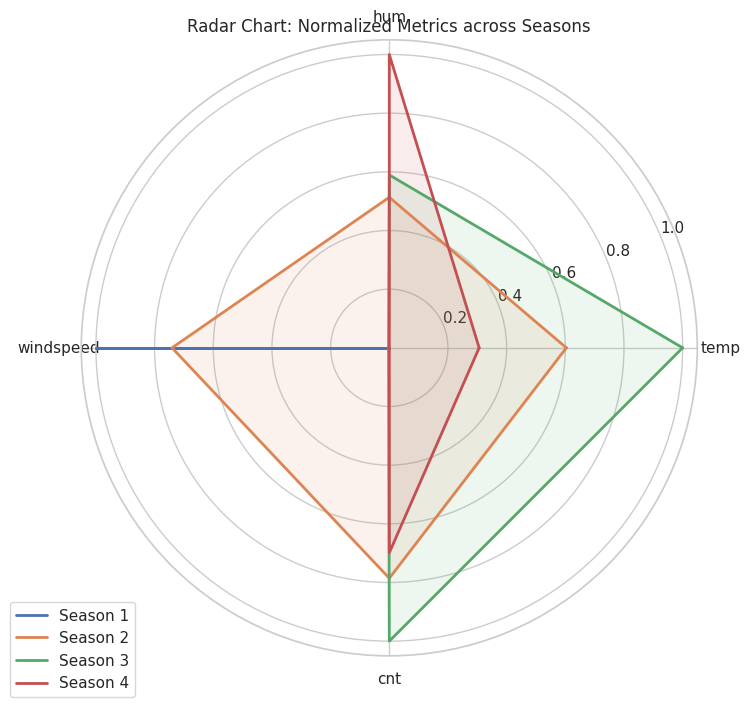

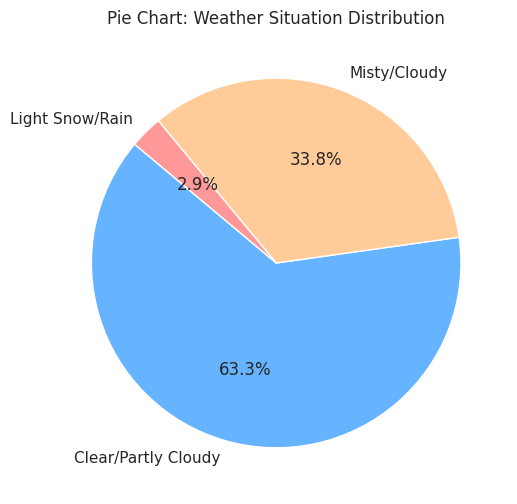

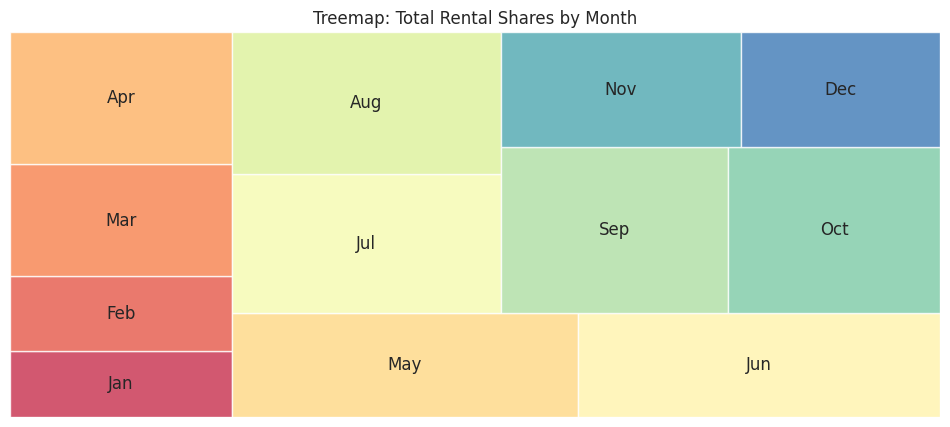

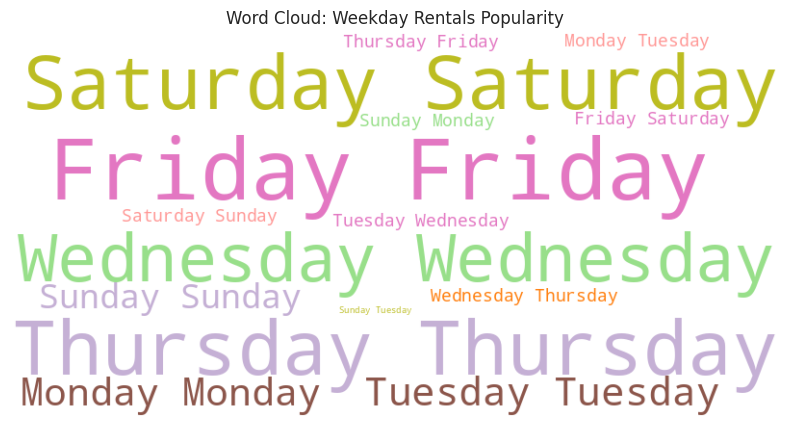

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify
from wordcloud import WordCloud
from sklearn.preprocessing import MinMaxScaler

# 1. Load the Day dataset
try:
    df_day = pd.read_csv('/content/day.csv')
    print("Day dataset (Bike Sharing) loaded successfully!")
    print(f"Shape: {df_day.shape}")
    print("Columns:", df_day.columns.tolist())
except Exception as e:
    print("Error loading day.csv:", e)

# 2. Data Cleaning & Preprocessing
# Check duplicates and drop if any
df_day = df_day.drop_duplicates()
print(f"Shape after removing duplicates: {df_day.shape}")
print("Missing values:\n", df_day.isnull().sum().sum())

# Set up plots
sns.set_theme(style="whitegrid")

# --- 1 & 2. Bar & Stacked Bar Plots ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df_day, x='season', palette='Set2', hue='season', legend=False, ax=axes[0])
axes[0].set_title("Bar Plot: Distribution across Seasons (1:Spring, 2:Summer, 3:Fall, 4:Winter)")

pivot_df = pd.crosstab(df_day['workingday'], df_day['weathersit'], normalize='index') * 100
pivot_df.plot(kind='bar', stacked=True, color=['#66b3ff', '#ffcc99', '#ff9999'], ax=axes[1])
axes[1].set_title('Stacked Bar: Weather Situation by Working Day')
axes[1].set_ylabel('Percentage')
axes[1].set_xticklabels(['Weekend/Holiday', 'Working Day'], rotation=0)
plt.tight_layout()
plt.show()

# --- 3, 4, & 5. Line, Scatter, & Bubble Plots ---
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
avg_cnt_by_month = df_day.groupby('mnth')['cnt'].mean().reset_index()
sns.lineplot(data=avg_cnt_by_month, x='mnth', y='cnt', color='indigo', marker='o', linewidth=2, ax=axes[0])
axes[0].set_title('Line Plot: Average Monthly Bike Rentals')

sns.scatterplot(data=df_day, x='temp', y='cnt', alpha=0.7, hue='yr', palette='coolwarm', s=60, ax=axes[1])
axes[1].set_title('Scatter Plot: Temp vs Total Rentals')

bubble_size = df_day['hum'] * 150
scatter = axes[2].scatter(df_day['temp'], df_day['windspeed'], c=df_day['cnt'], s=bubble_size, cmap='viridis', alpha=0.6)
fig.colorbar(scatter, ax=axes[2], label='Total Rentals (cnt)')
axes[2].set_title('Bubble Plot: Temp vs Windspeed (Size=Humidity)')
axes[2].set_xlabel('Normalized Temperature')
axes[2].set_ylabel('Normalized Windspeed')
plt.tight_layout()
plt.show()

# --- 6, 7, & 8. Histogram, Box Plot, & Heatmap ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(df_day['cnt'], kde=True, color='crimson', bins=20, ax=axes[0])
axes[0].set_title('Histogram: Distribution of Total Daily Bike Rentals')

sns.boxplot(data=df_day, x='season', y='cnt', palette='pastel', hue='season', legend=False, ax=axes[1])
axes[1].set_title("Box Plot: Bike Rental Distribution by Season")
plt.tight_layout()
plt.show()

# Heatmap
plt.figure(figsize=(11, 8))
numeric_cols = df_day.select_dtypes(include=[np.number]).drop(columns=['instant'])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# --- 9 & 10. Radar Chart & Pie Chart ---
season_means = df_day.groupby('season')[['temp', 'hum', 'windspeed', 'cnt']].mean()
scaler = MinMaxScaler()
scaled_season_means = pd.DataFrame(scaler.fit_transform(season_means), columns=season_means.columns, index=season_means.index)
categories = list(scaled_season_means.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for s in scaled_season_means.index:
    values = scaled_season_means.loc[s].values.tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=f'Season {s}')
    ax.fill(angles, values, alpha=0.1)
plt.xticks(angles[:-1], categories)
plt.title("Radar Chart: Normalized Metrics across Seasons")
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()

# Pie Chart
weather_counts = df_day['weathersit'].value_counts()
weather_labels = ['Clear/Partly Cloudy' if x==1 else ('Misty/Cloudy' if x==2 else 'Light Snow/Rain') for x in weather_counts.index]
plt.figure(figsize=(6, 6))
plt.pie(weather_counts, labels=weather_labels, autopct='%1.1f%%', colors=['#66b3ff','#ffcc99','#ff9999'], startangle=140)
plt.title('Pie Chart: Weather Situation Distribution')
plt.show()

# --- 11 & 12. Treemap & Word Cloud ---
month_cnt = df_day.groupby('mnth')['cnt'].sum()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(12, 5))
squarify.plot(sizes=month_cnt.values, label=month_names, alpha=0.8, color=sns.color_palette("Spectral", len(month_cnt)))
plt.axis('off')
plt.title("Treemap: Total Rental Shares by Month")
plt.show()

weekday_mapping = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
weighted_weekdays = " ".join([(weekday_mapping[row['weekday']] + " ") * int(row['cnt'] // 100) for _, row in df_day.iterrows()])
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='tab20').generate(weighted_weekdays)
plt.figure(figsize=(12, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Weekday Rentals Popularity')
plt.show()

## Working with student-mat.csv

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Load the Day dataset (Bike Sharing dataset)
try:
    df_Student = pd.read_csv('/content/student-mat.csv')
    print("Day dataset loaded successfully!")
    print(f"Shape: {df_Student.shape}")
    print("Columns:", df_Student.columns.tolist())
    display(df_Student.head())
except Exception as e:
    print("Error loading day.csv:", e)

Day dataset loaded successfully!
Shape: (395, 33)
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
# 2. Data Cleaning & Preprocessing
print("Initial Null Values:\n", df_Student.isnull().sum())
print(f"Duplicates count: {df_Student.duplicated().sum()}")

# Drop duplicates if any
df_Student = df_Student.drop_duplicates()

# Basic column summary
df_Student.info()

Initial Null Values:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Duplicates count: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null   

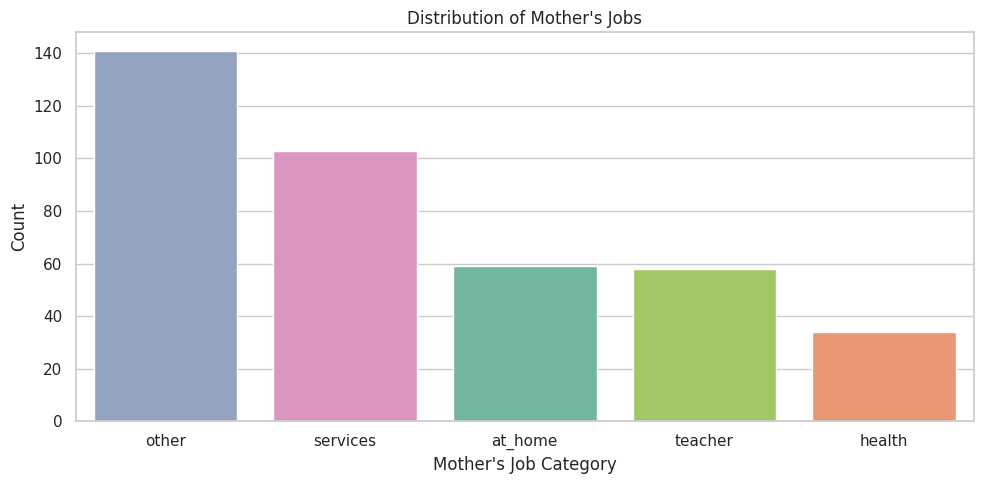

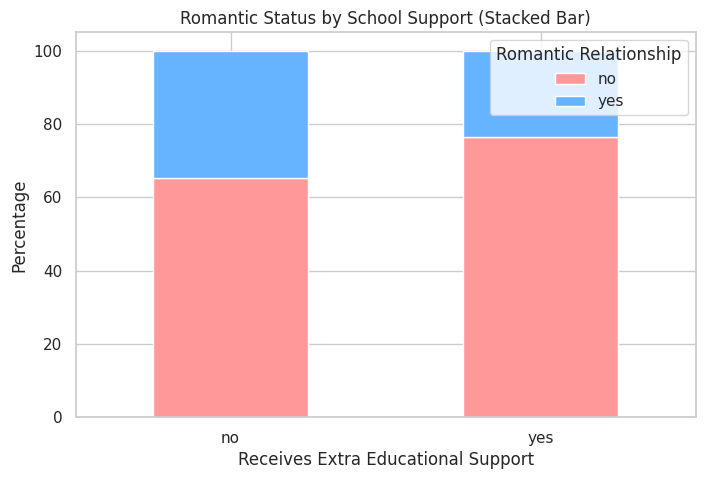

In [7]:
# Bar Plot: Student Job Distribution (Mother's Job)
plt.figure(figsize=(10, 5))
sns.countplot(data=df_Student, x='Mjob', order=df_Student['Mjob'].value_counts().index, palette='Set2', hue='Mjob', legend=False)
plt.title("Distribution of Mother's Jobs")
plt.xlabel("Mother's Job Category")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Stacked Bar Plot: School Support vs Romantic Relationship Status
pivot_df = pd.crosstab(df_Student['schoolsup'], df_Student['romantic'], normalize='index') * 100
pivot_df.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#ff9999', '#66b3ff'])
plt.title('Romantic Status by School Support (Stacked Bar)')
plt.ylabel('Percentage')
plt.xlabel('Receives Extra Educational Support')
plt.xticks(rotation=0)
plt.legend(title='Romantic Relationship')
plt.show()

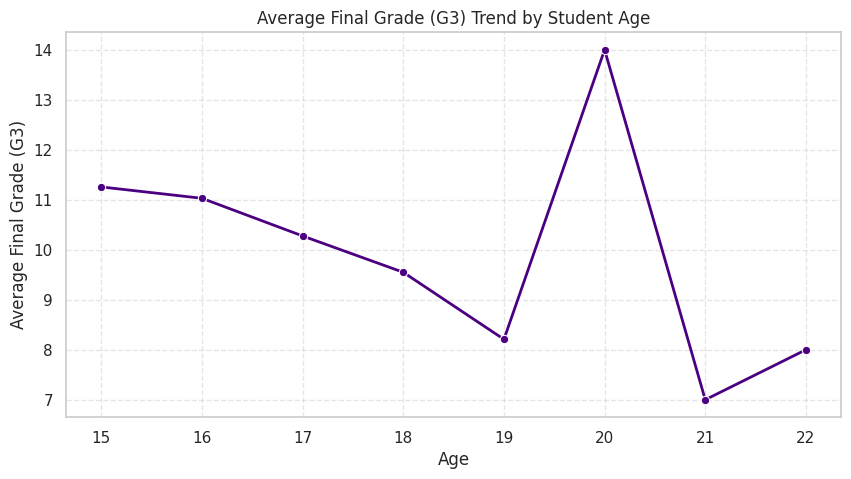

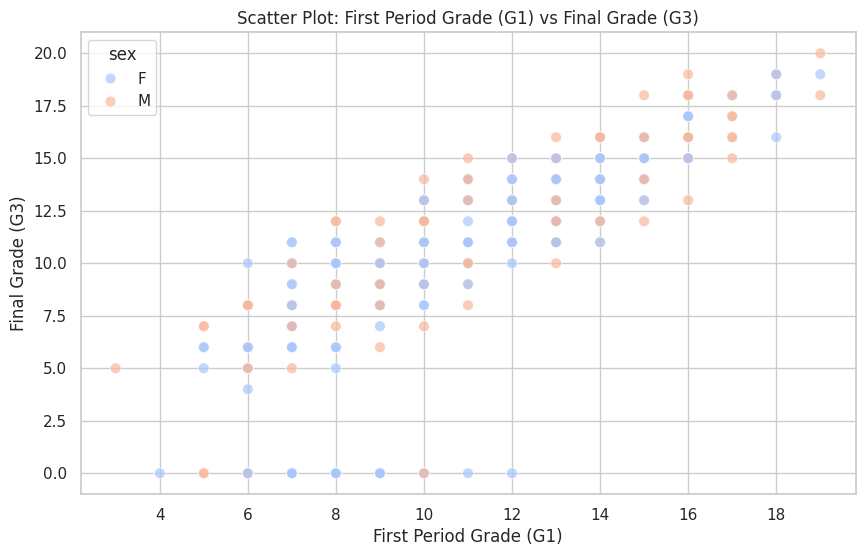

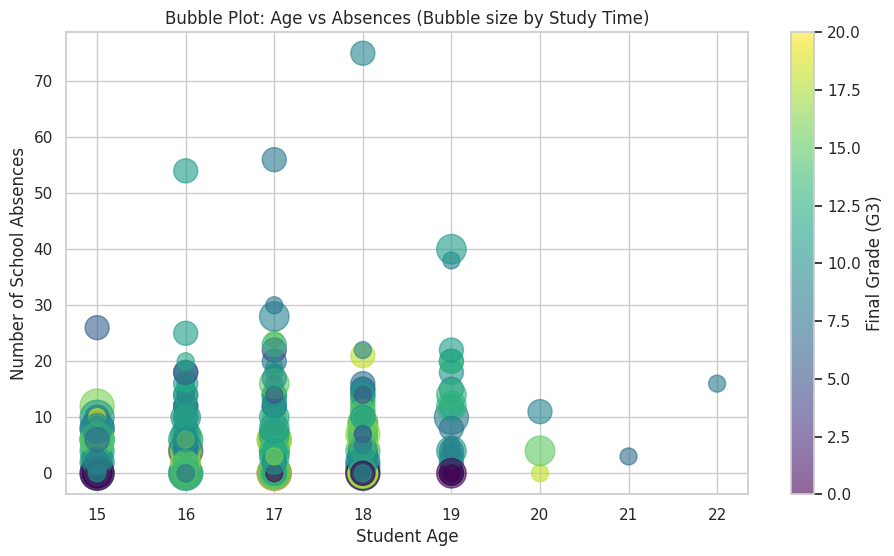

In [8]:
# Line Plot: Average Final Grade (G3) across Ages
avg_g3_by_age = df_Student.groupby('age')['G3'].mean().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(data=avg_g3_by_age, x='age', y='G3', color='indigo', marker='o', linewidth=2)
plt.title('Average Final Grade (G3) Trend by Student Age')
plt.xlabel('Age')
plt.ylabel('Average Final Grade (G3)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Scatter Plot: First Term Grade (G1) vs Final Grade (G3)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_Student, x='G1', y='G3', alpha=0.7, hue='sex', palette='coolwarm', s=60)
plt.title('Scatter Plot: First Period Grade (G1) vs Final Grade (G3)')
plt.xlabel('First Period Grade (G1)')
plt.ylabel('Final Grade (G3)')
plt.show()

# Bubble Plot: Student Age vs Absences (Size scaled by Study Time, color by Final Grade G3)
plt.figure(figsize=(11, 6))
# Scale up studytime for clearly visible bubble sizes (studytime range is typically 1 to 4)
bubble_size = df_Student['studytime'] * 150
scatter = plt.scatter(df_Student['age'], df_Student['absences'], c=df_Student['G3'],
                      s=bubble_size, cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label='Final Grade (G3)')
plt.title('Bubble Plot: Age vs Absences (Bubble size by Study Time)')
plt.xlabel('Student Age')
plt.ylabel('Number of School Absences')
plt.show()

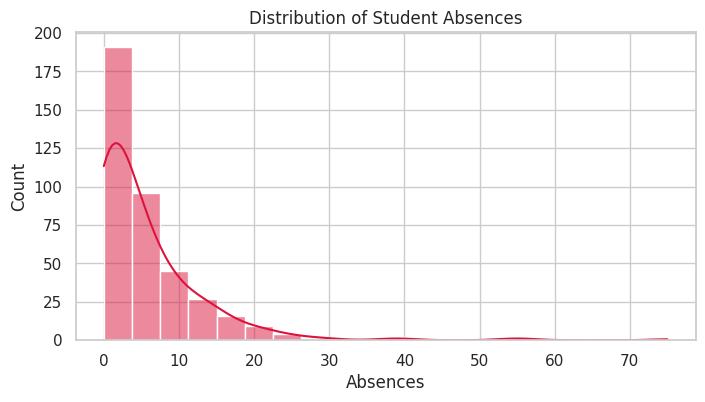

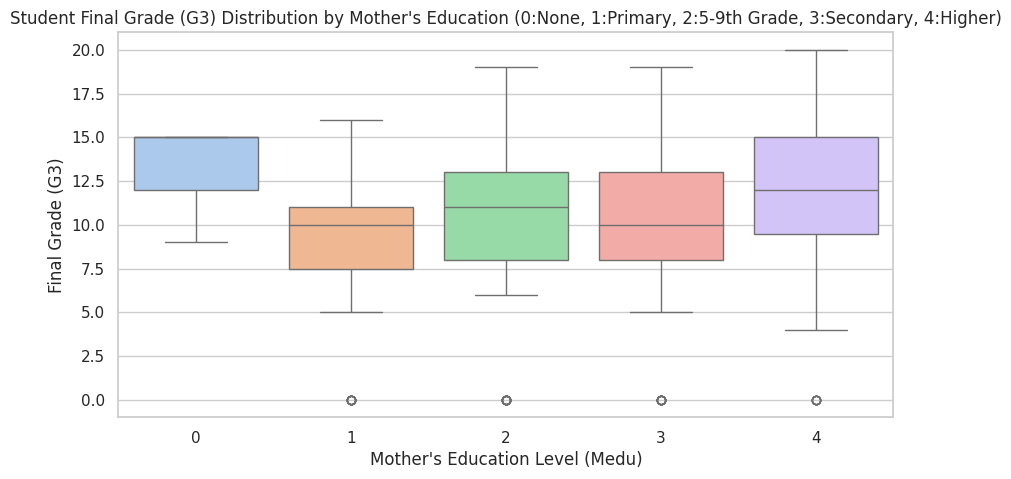

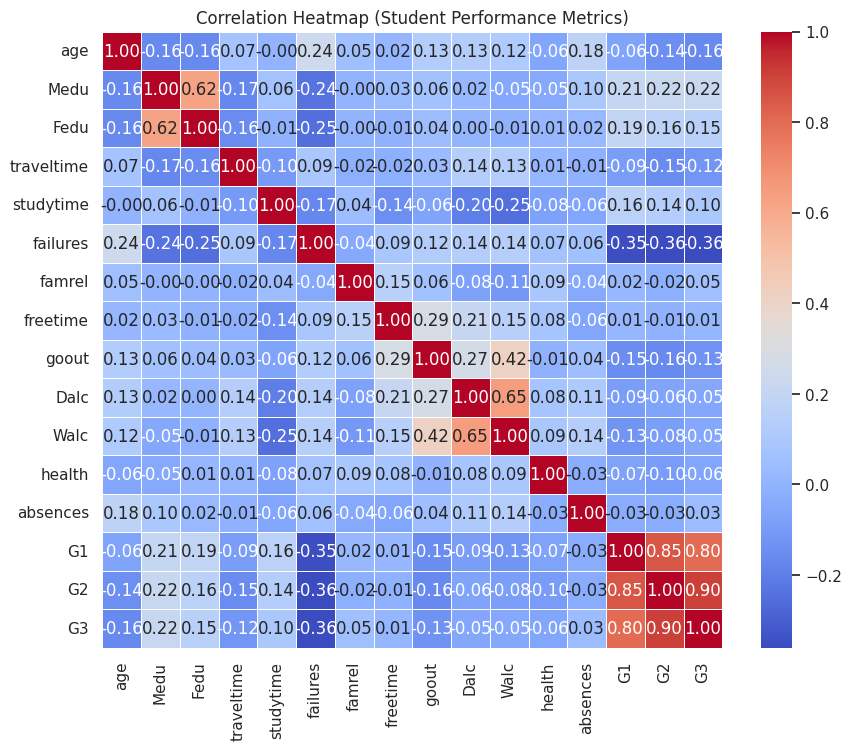

In [9]:
# Histogram of Student Absences
plt.figure(figsize=(8, 4))
sns.histplot(df_Student['absences'], kde=True, color='crimson', bins=20)
plt.title('Distribution of Student Absences')
plt.xlabel('Absences')
plt.show()

# Box Plot: Final Grades (G3) by Mother's Education Level (Medu)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_Student, x='Medu', y='G3', palette='pastel', hue='Medu', legend=False)
plt.title("Student Final Grade (G3) Distribution by Mother's Education (0:None, 1:Primary, 2:5-9th Grade, 3:Secondary, 4:Higher)")
plt.xlabel("Mother's Education Level (Medu)")
plt.ylabel("Final Grade (G3)")
plt.show()

# Heatmap: Correlation between numerical metrics in student dataset
plt.figure(figsize=(10, 8))
student_numeric_cols = df_Student.select_dtypes(include=[np.number])
sns.heatmap(student_numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap (Student Performance Metrics)')
plt.show()

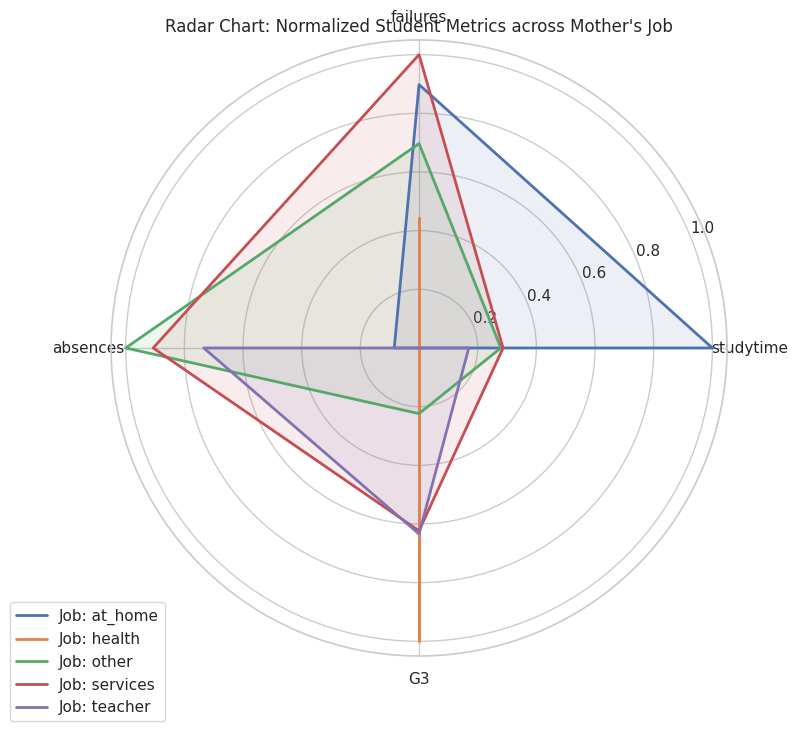

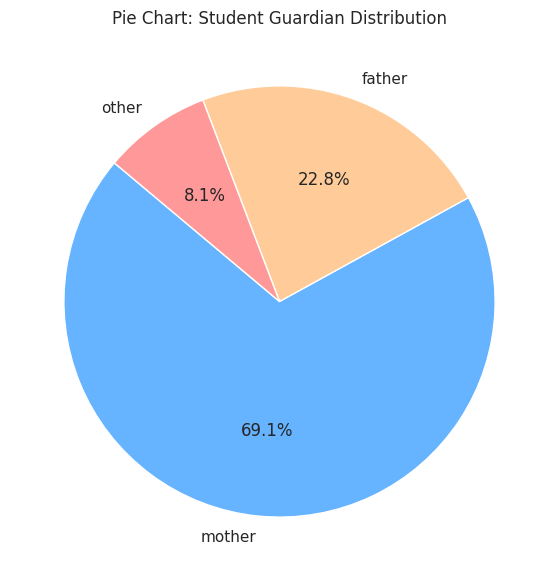

In [10]:
from sklearn.preprocessing import MinMaxScaler

# Radar Chart: Normalized Student Indicators Comparison across Mother's Job
job_means = df_Student.groupby('Mjob')[['studytime', 'failures', 'absences', 'G3']].mean()
scaler = MinMaxScaler()
scaled_job_means = pd.DataFrame(scaler.fit_transform(job_means), columns=job_means.columns, index=job_means.index)

categories = list(scaled_job_means.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for job in scaled_job_means.index:
    values = scaled_job_means.loc[job].values.tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f'Job: {job}')
    ax.fill(angles, values, alpha=0.1)

plt.xticks(angles[:-1], categories)
plt.title("Radar Chart: Normalized Student Metrics across Mother's Job")
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()

# Pie Chart: Guardian Distribution
guardian_counts = df_Student['guardian'].value_counts()
guardian_labels = guardian_counts.index.tolist()
plt.figure(figsize=(7, 7))
plt.pie(guardian_counts, labels=guardian_labels, autopct='%1.1f%%', colors=['#66b3ff','#ffcc99','#ff9999'], startangle=140)
plt.title('Pie Chart: Student Guardian Distribution')
plt.show()

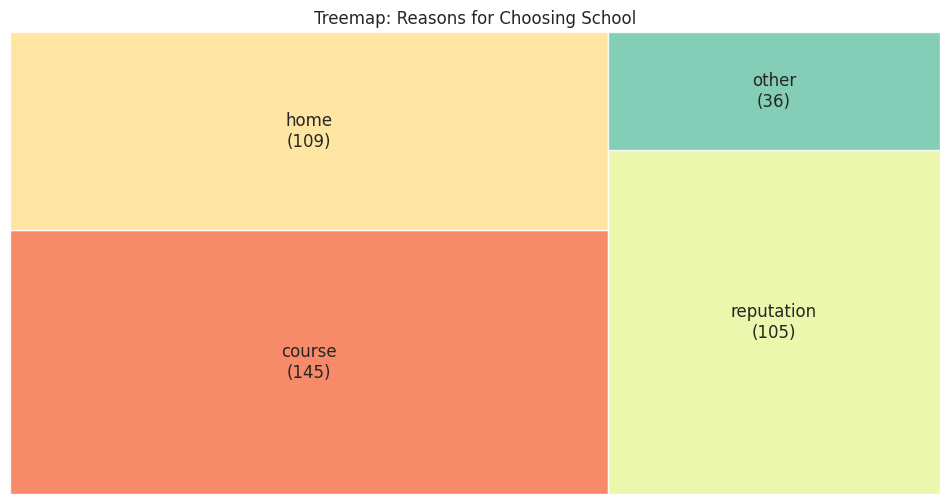

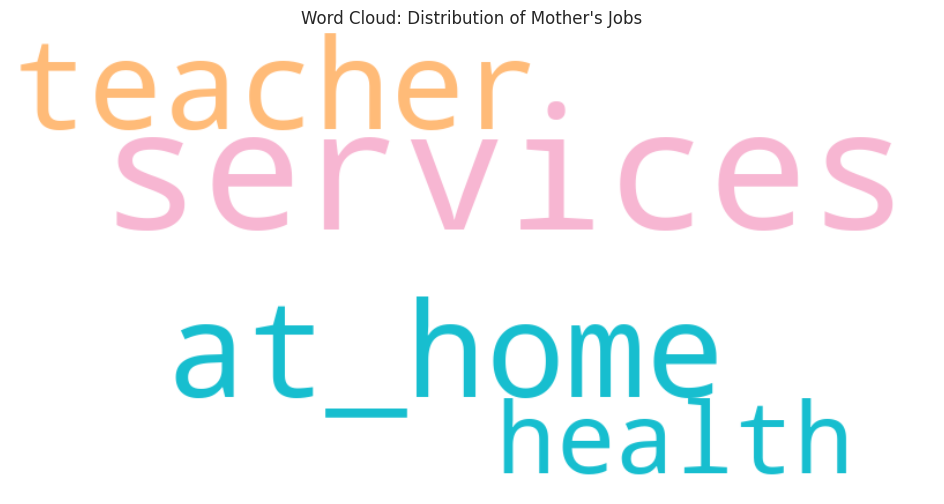

In [11]:
import squarify
from wordcloud import WordCloud

# Treemap: Distribution of Reasons to Choose School
reason_counts = df_Student['reason'].value_counts()
reason_labels = [f"{reason}\n({count})" for reason, count in zip(reason_counts.index, reason_counts.values)]

plt.figure(figsize=(12, 6))
squarify.plot(sizes=reason_counts.values, label=reason_labels, alpha=0.8, color=sns.color_palette("Spectral", len(reason_counts)))
plt.axis('off')
plt.title("Treemap: Reasons for Choosing School")
plt.show()

# Word Cloud of Mother's Job Categories scaled by occurrence frequency
mjob_text = " ".join(df_Student['Mjob'])
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='tab20').generate(mjob_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud: Distribution of Mother's Jobs")
plt.show()